<a href="https://colab.research.google.com/github/JxseDiaz/Deep-Learning/blob/main/Parcial_1_deep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de churn con un MLP – Telco Customer Churn
**DLY0100 Deep Learning – Evaluación Parcial N°1**
Integrantes: *Victoria Castillo – José Diaz*

## 1. Introducción
Queremos predecir si un cliente de una empresa de telecomunicaciones va a abandonar el servicio (churn) usando sus datos de contrato, servicios y cobros. Es un problema de clasificación binaria y lo resolvemos con una red neuronal multicapa (MLP) en Keras.

Solo cerca del 27% de los clientes abandona, así que mirar solo la accuracy no sirve (un modelo que siempre diga "no abandona" ya tendría ~73%). Por eso también usamos precision, recall y F1. Para la empresa es peor no detectar a un cliente que se va (falso negativo) que ofrecerle un descuento a uno que se iba a quedar, así que el recall es importante.

In [ ]:
import os, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
EPOCHS = 30          # épocas de los experimentos
EPOCHS_LARGO = 100   # para ver el efecto del número de épocas
keras.utils.set_random_seed(SEED)

## 2. Carga y preprocesamiento de datos

In [ ]:
archivo = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

if os.path.exists(archivo):
    df = pd.read_csv(archivo)
else:
    try:
        df = pd.read_csv(url)
    except Exception:
        from google.colab import files        # si falla la descarga, subir el CSV de Kaggle a mano
        subido = files.upload()
        df = pd.read_csv(io.BytesIO(next(iter(subido.values()))))

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


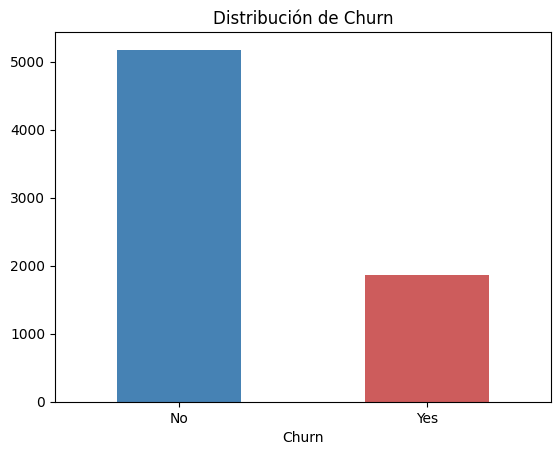

In [ ]:
print(df["Churn"].value_counts(normalize=True).round(3))
df["Churn"].value_counts().plot(kind="bar", color=["steelblue", "indianred"], rot=0, title="Distribución de Churn")
plt.show()